# 00 — Entendendo os dados MODIS × VIIRS
**Parte 1 — Análise:** quais colunas cada sensor tem, o que é idêntico, o que é diferente e o que precisa ser convertido.
**Parte 2 — Visualização:** gráficos que mostram *por que* as contagens não batem.

Pré-requisito: ter rodado `01_dados.ipynb` (ele baixa os Parquets em `data/raw`).

In [1]:
import io, requests, duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
RAW, PROC, REP = Path('../data/raw'), Path('../data/processed'), Path('../reports')
REP.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 30); plt.rcParams['figure.dpi'] = 110
con = duckdb.connect()
M = f"read_parquet('{RAW.as_posix()}/modis_*.parquet')"
V = f"read_parquet('{RAW.as_posix()}/viirs-snpp_*.parquet')"
q = lambda sql: con.execute(sql).df()

---
# PARTE 1 — ANÁLISE

## 1.1 De onde vêm os dados
NASA **FIRMS** (Fire Information for Resource Management System). Cada linha = **um pixel quente detectado** pelo satélite numa passagem.

| | MODIS | VIIRS |
|---|---|---|
| Satélites | Terra (desde nov/2000), Aqua (desde jul/2002) | S-NPP (desde jan/2012); NOAA-20/21 não usados aqui |
| Produto | MCD14ML Collection 6.1 | VNP14IMG v2 (375 m) |
| Pixel no nadir | **1 km** | **375 m** (≈ 7× menor em área) |
| Passagens (hora local) | Terra ~10:30 / 22:30 · Aqua ~13:30 / 01:30 | ~13:30 / 01:30 |

URL do arquivo anual por país: `https://firms.modaps.eosdis.nasa.gov/data/country/<modis|viirs-snpp>/<ano>/<fonte>_<ano>_Brazil.csv`

## 1.2 Todas as colunas originais
Os Parquets locais guardam só as colunas úteis. Para ver **todas**, lemos um pedaço (~2 MB) do CSV original de 2020.

In [2]:
def amostra_csv(fonte, ano=2020, nbytes=2_000_000):
    url = f'https://firms.modaps.eosdis.nasa.gov/data/country/{fonte}/{ano}/{fonte}_{ano}_Brazil.csv'
    txt = requests.get(url, headers={'Range': f'bytes=0-{nbytes}'}, timeout=60).text
    txt = txt[:txt.rfind('\n')]          # descarta a última linha cortada
    return pd.read_csv(io.StringIO(txt), dtype={'acq_time': str})

am_m, am_v = amostra_csv('modis'), amostra_csv('viirs-snpp')
print('MODIS:', list(am_m.columns)); print('VIIRS:', list(am_v.columns))
display(am_m.head(3)); display(am_v.head(3))

MODIS: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
VIIRS: ['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti5', 'frp', 'daynight', 'type']


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-22.9198,-43.7545,304.2,1.1,1.0,2020-01-01,0130,Terra,MODIS,38,6.03,290.1,5.2,N,2
1,-22.9076,-43.7345,314.9,1.1,1.0,2020-01-01,0130,Terra,MODIS,90,6.03,290.7,13.7,N,2
2,-22.4116,-47.1141,300.4,1.7,1.3,2020-01-01,0130,Terra,MODIS,28,6.03,287.4,7.9,N,0


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,-4.63446,-44.91713,308.78,0.39,0.36,2020-01-01,0418,N,VIIRS,n,2,282.10,1.23,N,0
1,-4.63391,-44.92061,330.37,0.39,0.36,2020-01-01,0418,N,VIIRS,n,2,282.50,3.17,N,0
2,-17.13729,-56.51095,300.08,0.35,0.57,2020-01-01,0422,N,VIIRS,n,2,279.92,0.87,N,0


## 1.3 Comparação de colunas (nomes)

In [3]:
cm, cv = set(am_m.columns), set(am_v.columns)
print('Mesmo nome nos dois :', sorted(cm & cv))
print('Só no MODIS        :', sorted(cm - cv))
print('Só no VIIRS        :', sorted(cv - cm))

Mesmo nome nos dois : ['acq_date', 'acq_time', 'confidence', 'daynight', 'frp', 'instrument', 'latitude', 'longitude', 'satellite', 'scan', 'track', 'type', 'version']
Só no MODIS        : ['bright_t31', 'brightness']
Só no VIIRS        : ['bright_ti4', 'bright_ti5']


## 1.4 Dicionário comparado — o que reaproveitar e o que converter
Ter **o mesmo nome não garante o mesmo significado**. Classificação:
- 🟢 **Idêntica** — mesmo significado e formato, reaproveita direto.
- 🟡 **Mesmo conceito, escala diferente** — precisa converter/padronizar.
- 🔴 **Específica do sensor** — não comparável; não usar na série harmonizada.

In [4]:
dic = pd.DataFrame([
 ('latitude, longitude', 'centro do pixel de ~1 km, 4 casas', 'centro do pixel de 375 m, 5 casas', '🟡', 'Mesma unidade, mas cada ponto representa uma área diferente → 1 ponto ≠ 1 incêndio'),
 ('acq_date',            'data UTC',                          'data UTC',                          '🟢', 'Reusa'),
 ('acq_time',            'HHMM UTC',                          'HHMM UTC',                          '🟢', 'Reusa (horários de passagem diferem — ver 1.7)'),
 ('daynight',            'D / N',                             'D / N',                             '🟢', 'Reusa'),
 ('type',                '0 veg · 1 vulcão · 2 estático · 3 offshore', 'mesmos códigos',           '🟡', 'Mesmos códigos, mas classificação feita separadamente por sensor → serve como filtro, não como dado idêntico'),
 ('instrument',          'MODIS',                             'VIIRS',                             '🟢', 'Vira a coluna "sensor"'),
 ('frp',                 'MW por pixel de ~1 km',             'MW por pixel de 375 m',             '🟡', 'Mesma unidade, mas pixel menor → FRP por ponto menor'),
 ('confidence',          'número 0–100',                      "categoria l / n / h",               '🟡', 'Padronizar: MODIS≥30 ≈ VIIRS n|h'),
 ('satellite',           'Terra / Aqua',                      'N (S-NPP)',                         '🟡', 'Mapear para nome do satélite'),
 ('scan, track',         'tamanho do pixel 1–4,8 km',         'tamanho do pixel 0,375–0,8 km',     '🟡', 'Explica a diferença de resolução'),
 ('version',             '6.1x',                              '2.x',                               '🟡', 'Só metadado'),
 ('brightness',          'temp. banda 21/22 (4 µm), K',       '— (bright_ti4: banda I4 3,74 µm)',  '🔴', 'Bandas diferentes, não comparar'),
 ('bright_t31',          'temp. banda 31 (11 µm), K',         '— (bright_ti5: banda I5 11,45 µm)', '🔴', 'Bandas diferentes, não comparar'),
], columns=['coluna','MODIS','VIIRS','status','o que fazer'])
dic

,coluna,MODIS,VIIRS,status,o que fazer
0,"latitude, longitude","centro do pixel de ~1 km, 4 casas","centro do pixel de 375 m, 5 casas",🟡,"Mesma unidade, mas cada ponto representa uma á..."
1,acq_date,data UTC,data UTC,🟢,Reusa
2,acq_time,HHMM UTC,HHMM UTC,🟢,Reusa (horários de passagem diferem — ver 1.7)
3,daynight,D / N,D / N,🟢,Reusa
4,type,0 veg · 1 vulcão · 2 estático · 3 offshore,mesmos códigos,🟡,"Mesmos códigos, mas classificação feita separa..."
5,instrument,MODIS,VIIRS,🟢,"Vira a coluna ""sensor"""
6,frp,MW por pixel de ~1 km,MW por pixel de 375 m,🟡,"Mesma unidade, mas pixel menor → FRP por ponto..."
7,confidence,número 0–100,categoria l / n / h,🟡,Padronizar: MODIS≥30 ≈ VIIRS n|h
8,satellite,Terra / Aqua,N (S-NPP),🟡,Mapear para nome do satélite
9,"scan, track","tamanho do pixel 1–4,8 km","tamanho do pixel 0,375–0,8 km",🟡,Explica a diferença de resolução


## 1.4b Verificação: as colunas 🟢 são mesmo idênticas?
A tabela acima vem da documentação. Aqui **testamos nos dados** cada coluna que parecia idêntica.
Critério: só é 🟢 se tiver **mesmo formato, mesma unidade e mesma regra de geração**.

In [5]:
am_m_s = amostra_csv('modis').astype(str); am_v_s = amostra_csv('viirs-snpp').astype(str)
casas = lambda s: s.str.split('.').str[1].str.len().value_counts(normalize=True).round(3).to_dict()
print('Casas decimais da latitude  — MODIS:', casas(am_m_s.latitude), '| VIIRS:', casas(am_v_s.latitude))
print('Exemplos acq_date           — MODIS:', am_m_s.acq_date.iloc[0], '| VIIRS:', am_v_s.acq_date.iloc[0])
print('Exemplos acq_time           — MODIS:', sorted(am_m_s.acq_time.unique())[:6], '| VIIRS:', sorted(am_v_s.acq_time.unique())[:6])
print('Valores daynight            — MODIS:', sorted(am_m_s.daynight.unique()), '| VIIRS:', sorted(am_v_s.daynight.unique()))

Casas decimais da latitude  — MODIS: {4: 0.9, 3: 0.09, 2: 0.01, 1: 0.001} | VIIRS: {5: 0.904, 4: 0.086, 3: 0.009, 2: 0.001, 1: 0.0}
Exemplos acq_date           — MODIS: 2020-01-01 | VIIRS: 2020-01-01
Exemplos acq_time           — MODIS: ['0015', '0020', '0021', '0026', '0027', '0032'] | VIIRS: ['0245', '0251', '0254', '0255', '0256', '0257']
Valores daynight            — MODIS: ['D', 'N'] | VIIRS: ['D', 'N']


**Teste do `daynight`:** se a regra for a mesma (ângulo solar zenital > 85° = noite, nos dados *standard*), a fração de 'D' por hora solar local deve ser 1 de dia e 0 de noite nos dois sensores.

In [6]:
dn = q(f'''
SELECT sensor, round(((acq_time::INT//100) + (acq_time::INT%100)/60 + longitude/15 + 24) % 24) hora_local,
       round(avg((daynight='D')::INT), 3) fracao_D, count(*) n
FROM (SELECT 'MODIS' sensor, * FROM {M} UNION ALL BY NAME SELECT 'VIIRS' sensor, * FROM {V})
GROUP BY ALL HAVING n > 10000 ORDER BY 1, 2''')
dn.pivot(index='hora_local', columns='sensor', values='fracao_D')

sensor,MODIS,VIIRS
hora_local,,
0.0,NaN,0.0
1.0,0.0,0.0
2.0,0.0,0.0
3.0,0.0,NaN
9.0,1.0,NaN
10.0,1.0,NaN
11.0,1.0,NaN
13.0,1.0,1.0
14.0,1.0,1.0


**Teste do `type`:** mesmos códigos, mas a proporção é igual?

In [7]:
tp = q(f'''SELECT 'MODIS' sensor, type, count(*) n FROM {M} GROUP BY ALL
          UNION ALL SELECT 'VIIRS', type, count(*) FROM {V} GROUP BY ALL''')
tp['% do sensor'] = (100 * tp.n / tp.groupby('sensor').n.transform('sum')).round(3)
tp.pivot(index='type', columns='sensor', values=['n', '% do sensor'])

n             % do sensor        
sensor      MODIS       VIIRS       MODIS   VIIRS
type                                             
0       9842208.0  18987191.0      98.749  98.741
2        124549.0    212937.0       1.250   1.107
3           133.0     29251.0       0.001   0.152

**Teste de unicidade:** cada linha é um pixel único (lat, lon, data, hora)?

In [8]:
for nome, src in [('MODIS', M), ('VIIRS', V)]:
    rep = q(f'SELECT count(*) - count(DISTINCT (latitude, longitude, acq_date, acq_time)) r FROM {src}').r[0]
    print(f'{nome}: linhas com mesmo pixel/data/hora repetido = {rep}')

MODIS: linhas com mesmo pixel/data/hora repetido = 0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

VIIRS: linhas com mesmo pixel/data/hora repetido = 5


### Veredito da verificação
| coluna | resultado do teste | status final |
|---|---|---|
| `acq_date` | AAAA-MM-DD em UTC nos dois | 🟢 **idêntica** |
| `acq_time` | HHMM em UTC, resolução de 1 minuto, nos dois | 🟢 **idêntica** (formato e regra); os *valores* diferem porque os satélites passam em horários diferentes |
| `daynight` | 'D' só entre ~9h e 15h locais e 'N' fora disso, nos dois → mesma regra | 🟢 **idêntica** |
| `instrument` | rótulo fixo (MODIS / VIIRS) | 🟢 **idêntica** (só identifica o sensor) |
| `latitude`, `longitude` | mesma unidade (graus, centro do pixel), mas MODIS tem 4 casas e VIIRS 5, e o pixel representa 1 km × 375 m | 🟡 **não idêntica** — reusar a posição, mas nunca comparar contagem de pontos diretamente |
| `type` | mesmos códigos, mas classificação feita por sensor (ex.: offshore 133 no MODIS × ~29 mil no VIIRS) | 🟡 **não idêntica** — usar só como filtro (`type = 0`) |

⚠️ **Atenção ao `acq_date`:** a data é UTC, não local. A passagem noturna do Terra (~22:30 local) já cai no **dia seguinte** em UTC. A regra é a mesma nos dois sensores, então não afeta a comparação, mas o calendário mensal pode ter focos de fim de mês contados no mês seguinte.

## 1.5 Volume de dados (Brasil)

In [9]:
vol = q(f'''
SELECT 'MODIS' sensor, satellite, count(*) n, min(acq_date) inicio, max(acq_date) fim FROM {M} GROUP BY ALL
UNION ALL
SELECT 'VIIRS', satellite, count(*), min(acq_date), max(acq_date) FROM {V} GROUP BY ALL
ORDER BY 1, 2''')
vol

,sensor,satellite,n,inicio,fim
0,MODIS,Aqua,6173230,2002-07-04,2025-12-31
1,MODIS,Terra,3793660,2001-01-01,2025-12-31
2,VIIRS,N,19229379,2012-01-20,2025-12-31


## 1.6 Qualidade: nulos e duplicatas

In [10]:
for nome, src in [('MODIS', M), ('VIIRS', V)]:
    cols = q(f'DESCRIBE SELECT * FROM {src}').column_name.tolist()
    nulos = q('SELECT ' + ', '.join(f'count(*) - count({c}) AS {c}' for c in cols) + f' FROM {src}')
    dup = q(f'SELECT count(*) - (SELECT count(*) FROM (SELECT DISTINCT * FROM {src})) d FROM {src}').d[0]
    print(f'{nome}: duplicatas exatas = {dup:,}'); display(nulos)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

MODIS: duplicatas exatas = 0


,latitude,longitude,acq_date,acq_time,satellite,confidence,frp,daynight,type
0,0,0,0,0,0,0,0,0,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

VIIRS: duplicatas exatas = 0


,latitude,longitude,acq_date,acq_time,satellite,confidence,frp,daynight,type
0,0,0,0,0,0,0,0,0,0


## 1.7 Colunas que precisam de padronização
### `type` — o que filtrar
Só `type = 0` (vegetação) entra na série. Os demais são flares de gás, indústria, vulcões.

In [11]:
t = q(f'''SELECT 'MODIS' sensor, type, count(*) n FROM {M} GROUP BY ALL
          UNION ALL SELECT 'VIIRS', type, count(*) FROM {V} GROUP BY ALL''')
t.pivot(index='type', columns='sensor', values='n')

sensor,MODIS,VIIRS
type,,
0,9842208,18987191
2,124549,212937
3,133,29251


### `confidence` — escalas diferentes

In [12]:
cm_ = q(f'''SELECT CASE WHEN TRY_CAST(confidence AS INT) < 30 THEN 'baixa (<30)'
                         WHEN TRY_CAST(confidence AS INT) < 80 THEN 'nominal (30-79)'
                         ELSE 'alta (>=80)' END classe, count(*) n FROM {M} GROUP BY 1''')
cv_ = q(f"SELECT CASE confidence WHEN 'l' THEN 'baixa (l)' WHEN 'n' THEN 'nominal (n)' ELSE 'alta (h)' END classe, count(*) n FROM {V} GROUP BY 1")
for nome, d in [('MODIS', cm_), ('VIIRS', cv_)]:
    d['%'] = (100 * d.n / d.n.sum()).round(1); print(nome); display(d.sort_values('classe'))

MODIS


,classe,n,%
0,alta (>=80),3402199,34.1
1,baixa (<30),505369,5.1
2,nominal (30-79),6059322,60.8


VIIRS


,classe,n,%
1,alta (h),1267561,6.6
0,baixa (l),1692847,8.8
2,nominal (n),16268971,84.6


### `frp` (potência radiativa do fogo, MW)

In [13]:
frp = q(f'''SELECT 'MODIS' sensor, quantile_cont(frp, [0.25,0.5,0.75,0.95]) q, avg(frp) media FROM {M} WHERE type=0
          UNION ALL SELECT 'VIIRS', quantile_cont(frp, [0.25,0.5,0.75,0.95]), avg(frp) FROM {V} WHERE type=0''')
frp[['p25','p50','p75','p95']] = pd.DataFrame(frp.q.tolist()); frp.drop(columns='q').round(1)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,sensor,media,p25,p50,p75,p95
0,MODIS,50.9,12.3,22.8,47.9,169.8
1,VIIRS,12.0,2.6,5.7,11.6,42.4


### Horário de passagem (hora solar local ≈ UTC + longitude/15)
Se os horários fossem diferentes, um sensor veria o fogo num momento do dia mais ativo que o outro.

In [14]:
hora = q(f'''
WITH h AS (
 SELECT satellite, (CAST(substr(lpad(acq_time,4,'0'),1,2) AS INT) + CAST(substr(lpad(acq_time,4,'0'),3,2) AS INT)/60 + longitude/15 + 24) % 24 AS hl
 FROM {M} WHERE year(CAST(acq_date AS DATE)) BETWEEN 2012 AND 2020
 UNION ALL
 SELECT 'S-NPP', (CAST(substr(lpad(acq_time,4,'0'),1,2) AS INT) + CAST(substr(lpad(acq_time,4,'0'),3,2) AS INT)/60 + longitude/15 + 24) % 24
 FROM {V} WHERE year(CAST(acq_date AS DATE)) BETWEEN 2012 AND 2020)
SELECT satellite, round(hl) hora_local, count(*) n FROM h GROUP BY ALL''')
hora.pivot_table(index='hora_local', columns='satellite', values='n', fill_value=0).astype(int).loc[lambda d: d.sum(1) > d.values.sum()*0.005]

C:\Users\vagne\AppData\Local\Temp\ipykernel_22260\3731648632.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  hora.pivot_table(index='hora_local', columns='satellite', values='n', fill_value=0).astype(int).loc[lambda d: d.sum(1) > d.values.sum()*0.005]


satellite,Aqua,S-NPP,Terra
hora_local,,,
0.0,0,125495,0
1.0,110620,2352440,0
2.0,91478,1178287,0
10.0,0,0,414446
11.0,0,0,355712
13.0,564472,3684367,0
14.0,1102977,4919152,0
15.0,2225,86800,0
22.0,0,0,177450


## 1.8 Resumo da Parte 1 — por que os dados são diferentes
1. **Resolução**: pixel VIIRS 375 m × MODIS 1 km. Um mesmo incêndio vira vários pontos no VIIRS, e fogos pequenos que o MODIS não vê aparecem no VIIRS.
2. **Sensibilidade / bandas**: bandas e limiares diferentes → `brightness` não é comparável; `confidence` tem escalas diferentes.
3. **Horários**: Terra passa ~10:30, Aqua e S-NPP ~13:30. **Aqua × S-NPP é o par mais justo** para calibrar.
4. **Períodos**: MODIS 2001→ (só Terra até jul/2002), VIIRS 2012→. **Sobreposição 2012–hoje** é onde aprendemos a conversão.

**Reaproveitar direto (verificado em 1.4b):** data, hora, dia/noite, instrument.
**Reaproveitar com cuidado:** lat/lon (pixel de tamanho diferente), type (só como filtro).
**Padronizar:** confidence (filtro equivalente), satellite (nomes), sensor.
**Não usar na harmonização:** brightness, bright_t31/ti5, scan/track (apenas explicativos).

---
# PARTE 2 — VISUALIZAÇÃO
Todas as figuras são salvas em `reports/`.

In [15]:
COR = {'MODIS': '#E69F00', 'VIIRS': '#0072B2'}   # paleta acessível (Okabe-Ito)
g = pd.read_parquet(PROC / 'grid_monthly.parquet')
salvar = lambda fig, nome: fig.savefig(REP / nome, bbox_inches='tight')

### 2.1 Mesmo dia, mesmo lugar: VIIRS vê muito mais pontos

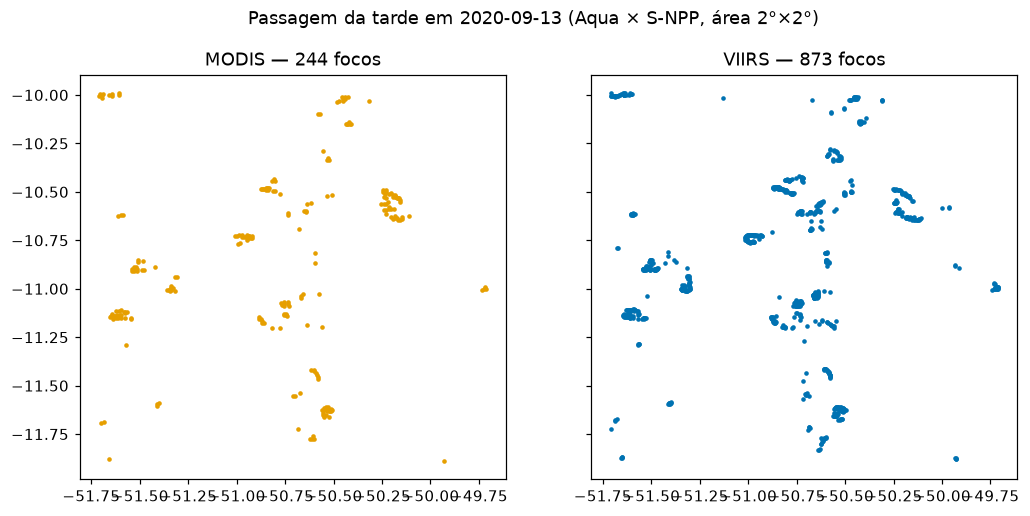

In [16]:
dia = q(f'''SELECT acq_date, count(*) n FROM {M} WHERE type=0 AND year(CAST(acq_date AS DATE))=2020 AND satellite='Aqua'
          GROUP BY 1 ORDER BY n DESC LIMIT 1''').acq_date[0]
pm = q(f"SELECT longitude, latitude FROM {M} WHERE acq_date='{dia}' AND satellite='Aqua' AND type=0")
lat0, lon0 = pm.latitude.median(), pm.longitude.median()
box = f'latitude BETWEEN {lat0-1} AND {lat0+1} AND longitude BETWEEN {lon0-1} AND {lon0+1}'
pm = q(f"SELECT longitude, latitude FROM {M} WHERE acq_date='{dia}' AND satellite='Aqua' AND type=0 AND {box}")
pv = q(f"SELECT longitude, latitude FROM {V} WHERE acq_date='{dia}' AND daynight='D' AND type=0 AND {box}")
fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for a, d, s in [(ax[0], pm, 'MODIS'), (ax[1], pv, 'VIIRS')]:
    a.scatter(d.longitude, d.latitude, s=4, c=COR[s]); a.set_title(f'{s} — {len(d)} focos'); a.set_aspect('equal')
fig.suptitle(f'Passagem da tarde em {dia} (Aqua × S-NPP, área 2°×2°)'); salvar(fig, 'v1_mesmo_dia.png')

### 2.2 Série anual: o 'degrau' de 2012

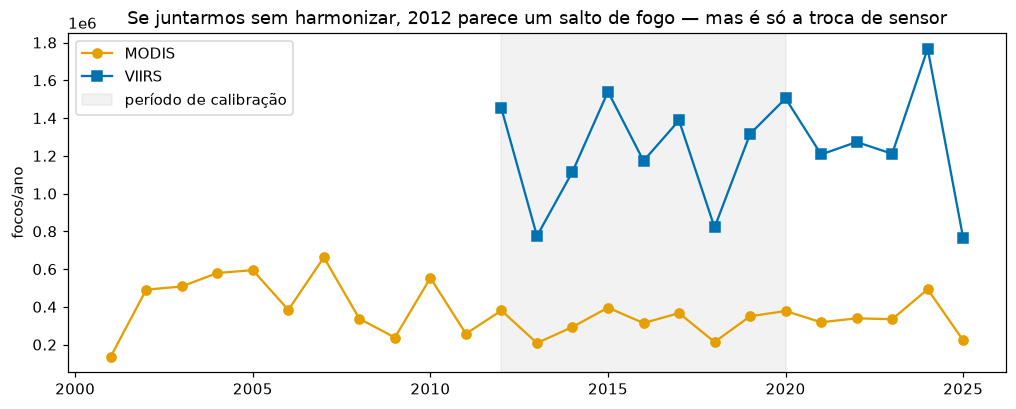

In [17]:
an = g.groupby('ano')[['n_modis', 'n_viirs']].sum().replace(0, np.nan)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(an.index, an.n_modis, 'o-', c=COR['MODIS'], label='MODIS')
ax.plot(an.index, an.n_viirs, 's-', c=COR['VIIRS'], label='VIIRS')
ax.axvspan(2012, 2020, alpha=.1, color='gray', label='período de calibração')
ax.set_ylabel('focos/ano'); ax.legend(); ax.set_title('Se juntarmos sem harmonizar, 2012 parece um salto de fogo — mas é só a troca de sensor')
salvar(fig, 'v2_serie_anual.png')

### 2.3 Razão VIIRS ÷ MODIS por ano — quão estável é?

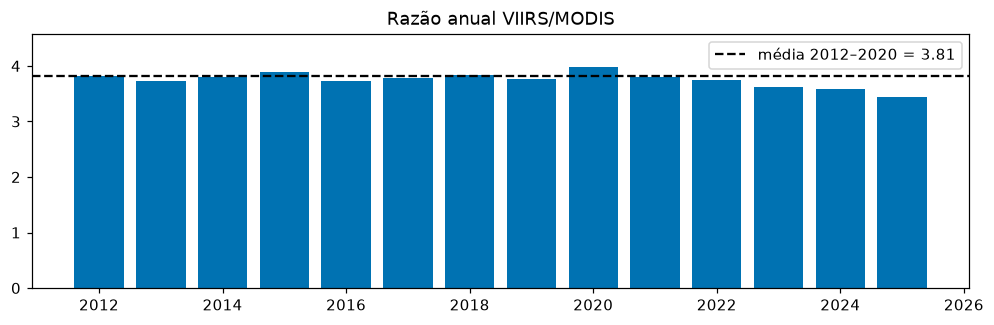

In [18]:
r = (an.n_viirs / an.n_modis).dropna()
fig, ax = plt.subplots(figsize=(11, 3)); ax.bar(r.index, r, color=COR['VIIRS'])
ax.axhline(r.loc[2012:2020].mean(), ls='--', c='k', label=f'média 2012–2020 = {r.loc[2012:2020].mean():.2f}')
ax.set_ylim(0, r.max()*1.15); ax.legend(); ax.set_title('Razão anual VIIRS/MODIS'); salvar(fig, 'v3_razao_anual.png')

### 2.4 Sazonalidade: a *forma* da curva é a mesma?
Se as curvas normalizadas coincidem, um fator de escala por mês resolve boa parte da harmonização.

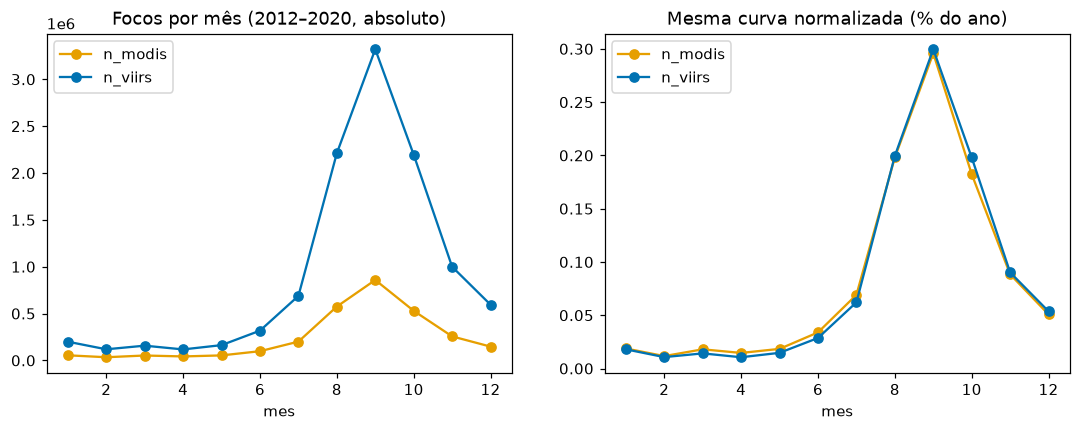

In [19]:
ov = g[g.ano.between(2012, 2020)].groupby('mes')[['n_modis', 'n_viirs']].sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ov.plot(ax=ax[0], color=[COR['MODIS'], COR['VIIRS']], marker='o', title='Focos por mês (2012–2020, absoluto)')
(ov / ov.sum()).plot(ax=ax[1], color=[COR['MODIS'], COR['VIIRS']], marker='o', title='Mesma curva normalizada (% do ano)')
salvar(fig, 'v4_sazonalidade.png')

### 2.5 Por célula e mês: relação MODIS × VIIRS (log-log)

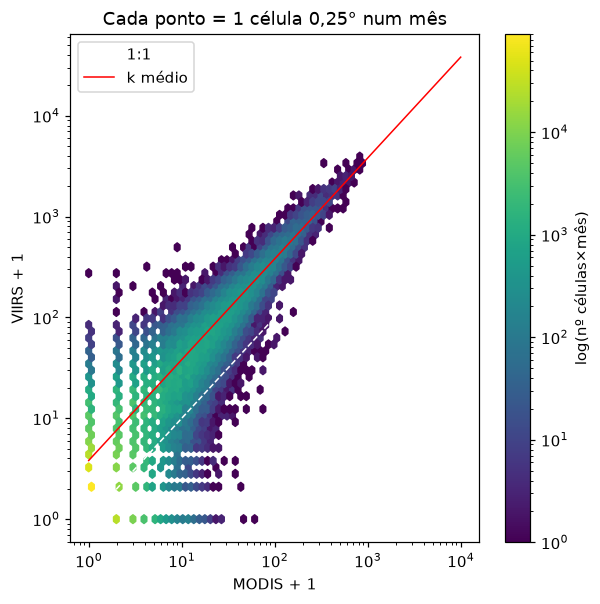

In [20]:
s = g[g.ano.between(2012, 2020) & ((g.n_modis > 0) | (g.n_viirs > 0))]
fig, ax = plt.subplots(figsize=(6, 6))
h = ax.hexbin(s.n_modis + 1, s.n_viirs + 1, xscale='log', yscale='log', gridsize=50, bins='log', cmap='viridis', mincnt=1)
x = np.logspace(0, 4); ax.plot(x, x, 'w--', lw=1, label='1:1'); ax.plot(x, x*r.loc[2012:2020].mean(), 'r-', lw=1, label='k médio')
ax.set_xlabel('MODIS + 1'); ax.set_ylabel('VIIRS + 1'); ax.legend(); fig.colorbar(h, label='log(nº células×mês)')
ax.set_title('Cada ponto = 1 célula 0,25° num mês'); salvar(fig, 'v5_scatter_celulas.png')

### 2.6 Mapa da razão VIIRS/MODIS por bloco 5° — ela varia no espaço?

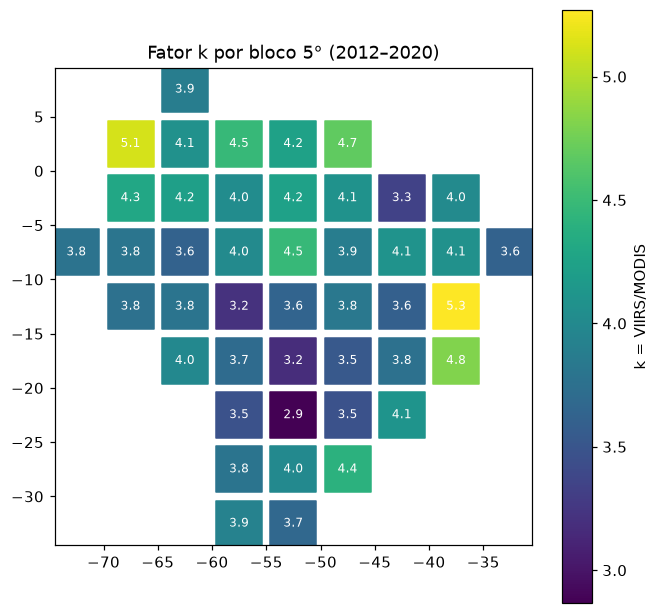

In [21]:
b = s.groupby(['bloco_lat', 'bloco_lon'])[['n_modis', 'n_viirs']].sum()
b = b[b.n_modis >= 100]; b['k'] = b.n_viirs / b.n_modis; b = b.reset_index()
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(b.bloco_lon + 2.5, b.bloco_lat + 2.5, c=b.k, s=900, marker='s', cmap='viridis')
for _, rr in b.iterrows(): ax.text(rr.bloco_lon + 2.5, rr.bloco_lat + 2.5, f'{rr.k:.1f}', ha='center', va='center', fontsize=8, color='w')
ax.set_aspect('equal'); fig.colorbar(sc, label='k = VIIRS/MODIS'); ax.set_title('Fator k por bloco 5° (2012–2020)'); salvar(fig, 'v6_mapa_k.png')

### 2.7 Distribuição de FRP — VIIRS capta fogos mais fracos

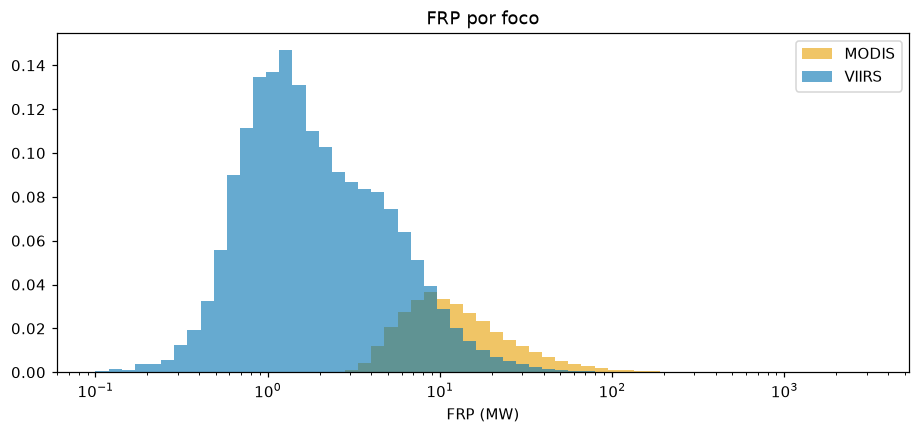

In [22]:
fr = q(f'''SELECT 'MODIS' s, frp FROM {M} WHERE type=0 AND frp>0 USING SAMPLE 200000
          UNION ALL SELECT 'VIIRS', frp FROM {V} WHERE type=0 AND frp>0 USING SAMPLE 200000''')
fig, ax = plt.subplots(figsize=(10, 4)); bins = np.logspace(-1, 3.5, 60)
for s_ in ['MODIS', 'VIIRS']: ax.hist(fr[fr.s == s_].frp, bins=bins, alpha=.6, color=COR[s_], label=s_, density=True)
ax.set_xscale('log'); ax.set_xlabel('FRP (MW)'); ax.legend(); ax.set_title('FRP por foco'); salvar(fig, 'v7_frp.png')

### 2.8 Horário de passagem por satélite

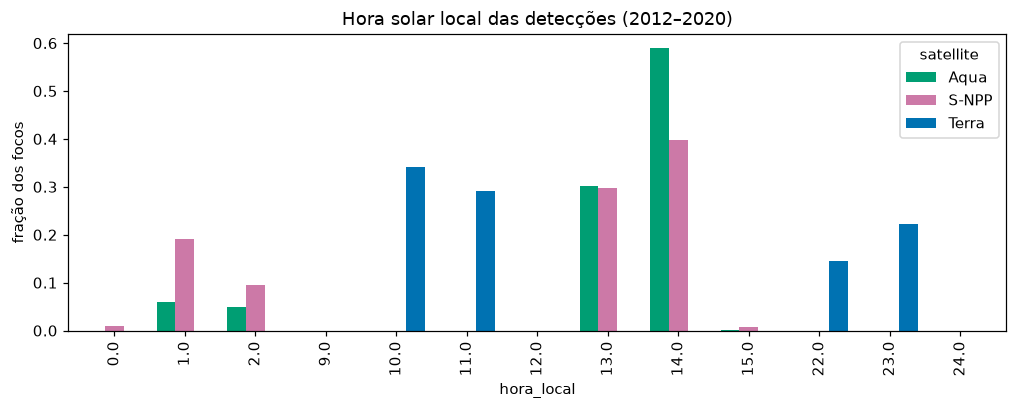

In [23]:
hp = hora.pivot_table(index='hora_local', columns='satellite', values='n', fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.5)); (hp / hp.sum()).plot.bar(ax=ax, width=.8, color=['#009E73', '#CC79A7', COR['VIIRS']])
ax.set_ylabel('fração dos focos'); ax.set_title('Hora solar local das detecções (2012–2020)'); salvar(fig, 'v8_horarios.png')

### 2.9 Prévia do calendário (ano × mês) para cada sensor

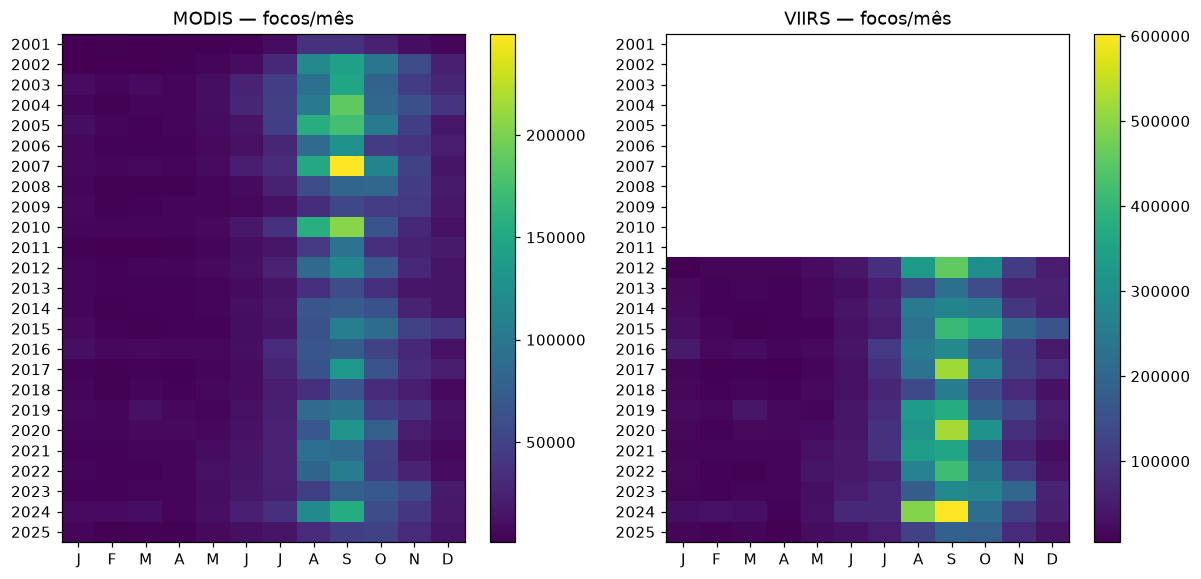

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
for a, col, nome in [(ax[0], 'n_modis', 'MODIS'), (ax[1], 'n_viirs', 'VIIRS')]:
    cal = g.pivot_table(index='ano', columns='mes', values=col, aggfunc='sum').replace(0, np.nan)
    im = a.imshow(cal, cmap='viridis', aspect='auto'); a.set_title(f'{nome} — focos/mês')
    a.set_yticks(range(len(cal)), cal.index); a.set_xticks(range(12), list('JFMAMJJASOND')); fig.colorbar(im, ax=a)
salvar(fig, 'v9_calendario_bruto.png')

## Resumo visual
- **2.1/2.5**: VIIRS conta ~4× mais pontos para o mesmo fogo.
- **2.2/2.3**: a razão é estável no tempo → harmonizar com fator é viável.
- **2.4**: a forma sazonal é praticamente igual → o calendário vai preservar os padrões.
- **2.6**: a razão muda no espaço → usar `k` por bloco, não um número único.
- **2.7**: VIIRS capta fogos mais fracos (FRP menor) → explica a diferença física.